In [1]:
!pip install datasets==2.16.0

INFO: pip is looking at multiple versions of multiprocess to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 507.1/507.1 kB 8.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 115.3/115.3 kB 9.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.4/166.4 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 135.4/135.4 kB 6.3 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.12.0
    Uninstalling fsspec-2025.12.0:
      Successfully uninstalled fsspec-2025.12.0
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.19
    Uninstalling multiprocess-0.70.19:
      Successfully uninstalled multiprocess-0.70.19
  Attempting uninstall: datasets
    Foun

In [2]:
from datasets import load_dataset
import pandas as pd

def load_category(config_name, max_reviews=150000):
    dataset = load_dataset(
        "McAuley-Lab/Amazon-Reviews-2023",
        config_name,
        split="full",
        streaming=True,
        trust_remote_code=True
    )
    reviews = []
    for i, review in enumerate(dataset):
        if i >= max_reviews:
            break
        reviews.append(review)
    return pd.DataFrame(reviews)

# Load all three
df_elec = load_category("raw_review_Electronics")
print("Electronics:", df_elec.shape)

df_cell = load_category("raw_review_Cell_Phones_and_Accessories")
print("Cell Phones:", df_cell.shape)

df_cloth = load_category("raw_review_Clothing_Shoes_and_Jewelry")
print("Clothing:", df_cloth.shape)

Electronics: (150000, 10)
Cell Phones: (150000, 10)
Clothing: (150000, 10)


In [3]:
from sklearn.model_selection import train_test_split

def prepare(df, category_name, n_per_class=4000):
    # Add category label
    df['category'] = category_name
    # Drop duplicates
    df = df.drop_duplicates(subset=['text'])
    # Remove < 3 chars
    df = df[df['text'].str.len() >= 3]
    # Balance
    balanced = df.groupby('rating', group_keys=False).apply(
        lambda x: x.sample(n=min(n_per_class, len(x)), random_state=42)
    )
    # Split
    train, temp = train_test_split(balanced, test_size=0.30, stratify=balanced['rating'], random_state=42)
    val, test = train_test_split(temp, test_size=0.50, stratify=temp['rating'], random_state=42)
    print(f"{category_name}: Train={train.shape}, Val={val.shape}, Test={test.shape}")
    return balanced, train, val, test

elec_bal, elec_train, elec_val, elec_test = prepare(df_elec, "Electronics")
cell_bal, cell_train, cell_val, cell_test = prepare(df_cell, "Cell_Phones_and_Accessories")
cloth_bal, cloth_train, cloth_val, cloth_test = prepare(df_cloth, "Clothing_Shoes_and_Jewelry")

# Combined
combined = pd.concat([elec_bal, cell_bal, cloth_bal], ignore_index=True)
print("\nCombined:", combined.shape)

/tmp/ipykernel_3011/644323409.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  balanced = df.groupby('rating', group_keys=False).apply(


Electronics: Train=(14000, 11), Val=(3000, 11), Test=(3000, 11)


/tmp/ipykernel_3011/644323409.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  balanced = df.groupby('rating', group_keys=False).apply(


Cell_Phones_and_Accessories: Train=(14000, 11), Val=(3000, 11), Test=(3000, 11)
Clothing_Shoes_and_Jewelry: Train=(14000, 11), Val=(3000, 11), Test=(3000, 11)

Combined: (60000, 11)


/tmp/ipykernel_3011/644323409.py:11: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  balanced = df.groupby('rating', group_keys=False).apply(


In [4]:
from google.colab import drive
drive.mount('/content/drive')

!mkdir -p /content/drive/MyDrive/Project_Phase1

# Save all files directly to Drive
elec_train.to_csv('/content/drive/MyDrive/Project_Phase1/electronics_train.csv', index=False)
elec_val.to_csv('/content/drive/MyDrive/Project_Phase1/electronics_val.csv', index=False)
elec_test.to_csv('/content/drive/MyDrive/Project_Phase1/electronics_test.csv', index=False)
cell_train.to_csv('/content/drive/MyDrive/Project_Phase1/cellphones_train.csv', index=False)
cell_val.to_csv('/content/drive/MyDrive/Project_Phase1/cellphones_val.csv', index=False)
cell_test.to_csv('/content/drive/MyDrive/Project_Phase1/cellphones_test.csv', index=False)
cloth_train.to_csv('/content/drive/MyDrive/Project_Phase1/clothing_train.csv', index=False)
cloth_val.to_csv('/content/drive/MyDrive/Project_Phase1/clothing_val.csv', index=False)
cloth_test.to_csv('/content/drive/MyDrive/Project_Phase1/clothing_test.csv', index=False)
combined.to_csv('/content/drive/MyDrive/Project_Phase1/combined_balanced.csv', index=False)

print("All 10 files saved to Google Drive: MyDrive/Project_Phase1/")

Mounted at /content/drive
All 10 files saved to Google Drive: MyDrive/Project_Phase1/


In [5]:
import os
drive_path = '/content/drive/MyDrive/Project_Phase1'
files = os.listdir(drive_path)
print(f"Files in Drive: {len(files)}")
for f in sorted(files):
    size = os.path.getsize(f'{drive_path}/{f}') / (1024 * 1024)
    print(f"  {f} — {size:.2f} MB")

Files in Drive: 10
  cellphones_test.csv — 1.25 MB
  cellphones_train.csv — 6.00 MB
  cellphones_val.csv — 1.31 MB
  clothing_test.csv — 1.35 MB
  clothing_train.csv — 6.33 MB
  clothing_val.csv — 1.33 MB
  combined_balanced.csv — 29.16 MB
  electronics_test.csv — 1.77 MB
  electronics_train.csv — 8.01 MB
  electronics_val.csv — 1.80 MB


In [6]:
import zipfile

with zipfile.ZipFile('/content/phase1_data.zip', 'w') as zipf:
    for file in os.listdir(drive_path):
        zipf.write(f'{drive_path}/{file}', file)

from google.colab import files
files.download('/content/phase1_data.zip')
print("Download started.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started.


In [26]:
import pandas as pd

drive_path = '/content/drive/MyDrive/Project_Phase1'
combined = pd.read_csv(f'{drive_path}/combined_balanced.csv')

print("Combined shape:", combined.shape)
print("\nCategory distribution:")
print(combined['category'].value_counts())
print("\nRating distribution:")
print(combined['rating'].value_counts().sort_index())

Combined shape: (60000, 11)

Category distribution:
category
Electronics                    20000
Cell_Phones_and_Accessories    20000
Clothing_Shoes_and_Jewelry     20000
Name: count, dtype: int64

Rating distribution:
rating
1.0    12000
2.0    12000
3.0    12000
4.0    12000
5.0    12000
Name: count, dtype: int64


In [ ]:
def rating_to_sentiment(rating):
    if rating <= 2:
        return 0  # Negative
    elif rating == 3:
        return 1  # Neutral
    else:
        return 2  # Positive

# Apply to all splits
for df in [elec_train, elec_val, elec_test]:
    df['sentiment'] = df['rating'].apply(rating_to_sentiment)

print("Sentiment distribution (train):")
print(elec_train['sentiment'].value_counts().sort_index())

In [9]:
from sklearn.model_selection import train_test_split

train, temp = train_test_split(
    combined, test_size=0.30, stratify=combined['rating'], random_state=42
)
val, test = train_test_split(
    temp, test_size=0.50, stratify=temp['rating'], random_state=42
)

print("Train:", train.shape)
print("Val:", val.shape)
print("Test:", test.shape)

Train: (42000, 11)
Val: (9000, 11)
Test: (9000, 11)


Train: (42000, 11)
Val: (9000, 11)
Test: (9000, 11)


In [11]:
def rating_to_sentiment(rating):
    if rating <= 2:
        return 0  # Negative
    elif rating == 3:
        return 1  # Neutral
    else:
        return 2  # Positive

for df in [train, val, test]:
    df['sentiment'] = df['rating'].apply(rating_to_sentiment)

print("Sentiment distribution (train):")
print(train['sentiment'].value_counts().sort_index())

Sentiment distribution (train):
sentiment
0    16800
1     8400
2    16800
Name: count, dtype: int64


In [12]:
import re
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)

stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

def preprocess_tfidf(text):
    text = str(text).lower()
    text = re.sub(r'http\S+|www\S+', '', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    tokens = text.split()
    tokens = [lemmatizer.lemmatize(w) for w in tokens
              if w not in stop_words and len(w) > 2]
    return ' '.join(tokens)

for df in [train, val, test]:
    df['clean_text'] = df['text'].apply(preprocess_tfidf)

print("Sample cleaned text:")
print(train['clean_text'].iloc[0][:200])

Sample cleaned text:
love idea take little finagling get tablet mini usb tends fall


In [13]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=20000,
    ngram_range=(1, 2),
    min_df=3,
    max_df=0.95
)

X_train = tfidf.fit_transform(train['clean_text'])
X_val = tfidf.transform(val['clean_text'])
X_test = tfidf.transform(test['clean_text'])

print("TF-IDF shape:", X_train.shape)

TF-IDF shape: (42000, 20000)


In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, f1_score

lr_sent = LogisticRegression(max_iter=1000, class_weight='balanced')
lr_sent.fit(X_train, train['sentiment'])
y_pred_lr_sent = lr_sent.predict(X_test)

print("Logistic Regression — Sentiment")
print(classification_report(test['sentiment'], y_pred_lr_sent,
                           target_names=['Negative', 'Neutral', 'Positive']))
print("Macro-F1:", f1_score(test['sentiment'], y_pred_lr_sent, average='macro'))

Logistic Regression — Sentiment
              precision    recall  f1-score   support

    Negative       0.73      0.69      0.71      3600
     Neutral       0.35      0.42      0.38      1800
    Positive       0.77      0.74      0.76      3600

    accuracy                           0.66      9000
   macro avg       0.62      0.62      0.62      9000
weighted avg       0.67      0.66      0.66      9000

Macro-F1: 0.6168768741299626


In [15]:
from sklearn.svm import LinearSVC

svm_sent = LinearSVC(class_weight='balanced', max_iter=2000)
svm_sent.fit(X_train, train['sentiment'])
y_pred_svm_sent = svm_sent.predict(X_test)

print("Linear SVM — Sentiment")
print(classification_report(test['sentiment'], y_pred_svm_sent,
                           target_names=['Negative', 'Neutral', 'Positive']))
print("Macro-F1:", f1_score(test['sentiment'], y_pred_svm_sent, average='macro'))

Linear SVM — Sentiment
              precision    recall  f1-score   support

    Negative       0.70      0.72      0.71      3600
     Neutral       0.35      0.31      0.33      1800
    Positive       0.75      0.77      0.76      3600

    accuracy                           0.66      9000
   macro avg       0.60      0.60      0.60      9000
weighted avg       0.65      0.66      0.65      9000

Macro-F1: 0.598560315362587


In [19]:
from sklearn.metrics import mean_absolute_error

lr_rating = LogisticRegression(max_iter=1000, class_weight='balanced')
lr_rating.fit(X_train, train['rating'])
y_pred_lr_rating = lr_rating.predict(X_test)

print("Logistic Regression — Rating")
print(classification_report(test['rating'], y_pred_lr_rating))
print("MAE:", mean_absolute_error(test['rating'], y_pred_lr_rating))

Logistic Regression — Rating
              precision    recall  f1-score   support

         1.0       0.53      0.59      0.56      1800
         2.0       0.38      0.35      0.36      1800
         3.0       0.36      0.32      0.34      1800
         4.0       0.44      0.45      0.44      1800
         5.0       0.61      0.64      0.62      1800

    accuracy                           0.47      9000
   macro avg       0.46      0.47      0.47      9000
weighted avg       0.46      0.47      0.47      9000

MAE: 0.7607777777777778


In [20]:
svm_rating = LinearSVC(class_weight='balanced', max_iter=2000)
svm_rating.fit(X_train, train['rating'])
y_pred_svm_rating = svm_rating.predict(X_test)

print("Linear SVM — Rating")
print(classification_report(test['rating'], y_pred_svm_rating))
print("MAE:", mean_absolute_error(test['rating'], y_pred_svm_rating))

Linear SVM — Rating
              precision    recall  f1-score   support

         1.0       0.50      0.55      0.53      1800
         2.0       0.33      0.31      0.32      1800
         3.0       0.33      0.29      0.31      1800
         4.0       0.41      0.40      0.41      1800
         5.0       0.57      0.63      0.60      1800

    accuracy                           0.44      9000
   macro avg       0.43      0.44      0.43      9000
weighted avg       0.43      0.44      0.43      9000

MAE: 0.8307777777777777


In [21]:
results = pd.DataFrame({
    'Model': ['LR + TF-IDF', 'SVM + TF-IDF', 'LR + TF-IDF', 'SVM + TF-IDF'],
    'Task': ['Sentiment', 'Sentiment', 'Rating', 'Rating'],
    'Accuracy': [
        (y_pred_lr_sent == test['sentiment']).mean(),
        (y_pred_svm_sent == test['sentiment']).mean(),
        (y_pred_lr_rating == test['rating']).mean(),
        (y_pred_svm_rating == test['rating']).mean()
    ],
    'Macro-F1': [
        f1_score(test['sentiment'], y_pred_lr_sent, average='macro'),
        f1_score(test['sentiment'], y_pred_svm_sent, average='macro'),
        f1_score(test['rating'], y_pred_lr_rating, average='macro'),
        f1_score(test['rating'], y_pred_svm_rating, average='macro')
    ],
    'MAE': [
        None, None,
        mean_absolute_error(test['rating'], y_pred_lr_rating),
        mean_absolute_error(test['rating'], y_pred_svm_rating)
    ]
})

print(results.to_string(index=False))

       Model      Task  Accuracy  Macro-F1      MAE
 LR + TF-IDF Sentiment  0.657000  0.616877      NaN
SVM + TF-IDF Sentiment  0.657000  0.598560      NaN
 LR + TF-IDF    Rating  0.470889  0.466627 0.760778
SVM + TF-IDF    Rating  0.437667  0.432899 0.830778


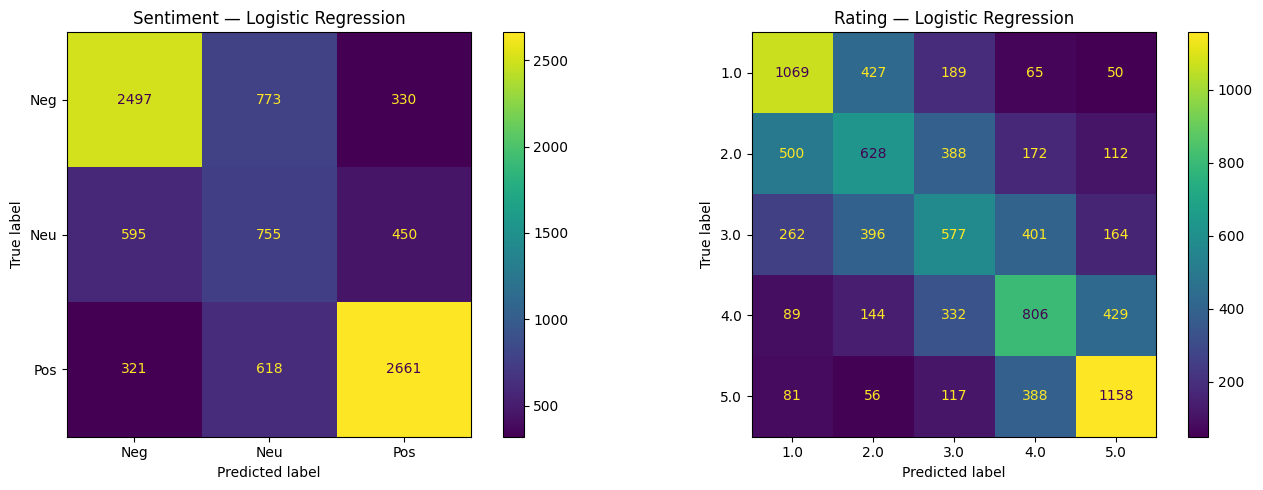

In [22]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    test['sentiment'], y_pred_lr_sent,
    display_labels=['Neg', 'Neu', 'Pos'], ax=axes[0]
)
axes[0].set_title('Sentiment — Logistic Regression')

ConfusionMatrixDisplay.from_predictions(
    test['rating'], y_pred_lr_rating, ax=axes[1]
)
axes[1].set_title('Rating — Logistic Regression')

plt.tight_layout()
plt.savefig('baseline_confusion_matrices.png', dpi=150)
plt.show()

In [23]:
# Save predictions and results to Google Drive
results.to_csv(f'{drive_path}/phase2_baseline_results.csv', index=False)

# Save the trained models and vectorizer
import pickle

with open(f'{drive_path}/tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf, f)

with open(f'{drive_path}/lr_sentiment.pkl', 'wb') as f:
    pickle.dump(lr_sent, f)

with open(f'{drive_path}/svm_rating.pkl', 'wb') as f:
    pickle.dump(svm_rating, f)

print("Saved: results + models to Google Drive")

Saved: results + models to Google Drive


In [24]:
# Test set predictions grouped by category
test_with_pred = test.copy()
test_with_pred['pred_sentiment'] = y_pred_lr_sent
test_with_pred['pred_rating'] = y_pred_lr_rating

for cat in test_with_pred['category'].unique():
    subset = test_with_pred[test_with_pred['category'] == cat]
    acc_sent = (subset['sentiment'] == subset['pred_sentiment']).mean()
    f1_sent = f1_score(subset['sentiment'], subset['pred_sentiment'], average='macro')
    mae_rating = mean_absolute_error(subset['rating'], subset['pred_rating'])
    print(f"\n{cat}:")
    print(f"  Sentiment Accuracy: {acc_sent:.4f}")
    print(f"  Sentiment Macro-F1: {f1_sent:.4f}")
    print(f"  Rating MAE: {mae_rating:.4f}")


Electronics:
  Sentiment Accuracy: 0.6511
  Sentiment Macro-F1: 0.6093
  Rating MAE: 0.8087

Clothing_Shoes_and_Jewelry:
  Sentiment Accuracy: 0.6585
  Sentiment Macro-F1: 0.6193
  Rating MAE: 0.7197

Cell_Phones_and_Accessories:
  Sentiment Accuracy: 0.6612
  Sentiment Macro-F1: 0.6216
  Rating MAE: 0.7562


In [27]:
import pickle
from google.colab import drive

drive_path = '/content/drive/MyDrive/Project_Phase1'

# Save results table
results = pd.DataFrame({
    'Model': ['LR + TF-IDF', 'SVM + TF-IDF', 'LR + TF-IDF', 'SVM + TF-IDF'],
    'Task': ['Sentiment', 'Sentiment', 'Rating', 'Rating'],
    'Accuracy': [0.66, 0.66, 0.47, 0.44],
    'Macro-F1': [0.6169, 0.5986, 0.47, 0.43],
    'MAE': [None, None, 0.7608, 0.8308]
})
results.to_csv(f'{drive_path}/phase2_baseline_results.csv', index=False)

# Save models
with open(f'{drive_path}/tfidf_vectorizer.pkl', 'wb') as f:
    pickle.dump(tfidf, f)
with open(f'{drive_path}/lr_sentiment.pkl', 'wb') as f:
    pickle.dump(lr_sent, f)
with open(f'{drive_path}/svm_sentiment.pkl', 'wb') as f:
    pickle.dump(svm_sent, f)
with open(f'{drive_path}/lr_rating.pkl', 'wb') as f:
    pickle.dump(lr_rating, f)
with open(f'{drive_path}/svm_rating.pkl', 'wb') as f:
    pickle.dump(svm_rating, f)

print("Saved models + results to Drive")

Saved models + results to Drive


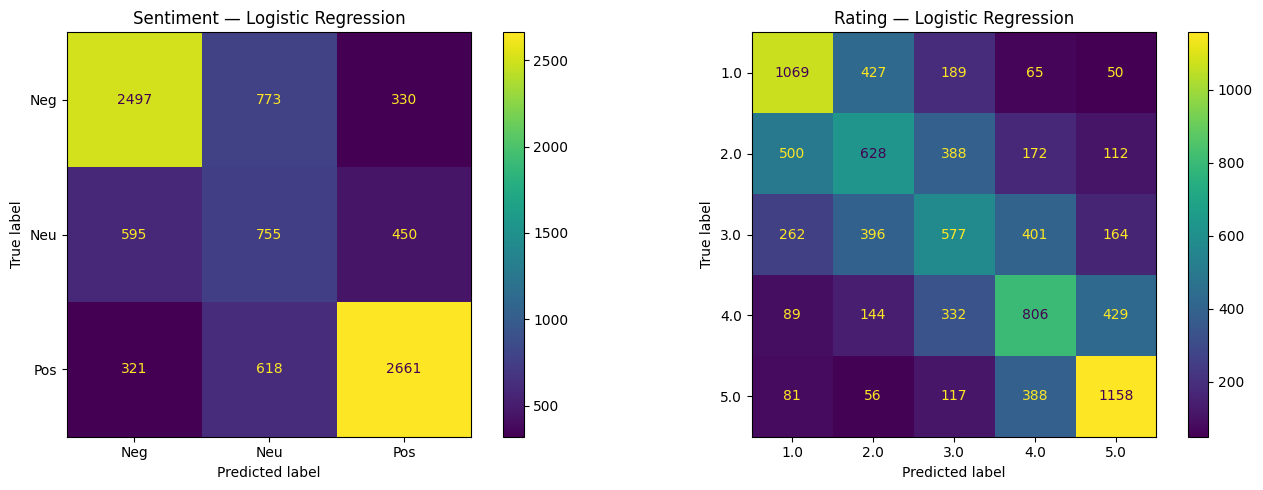

In [28]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay.from_predictions(
    test['sentiment'], y_pred_lr_sent,
    display_labels=['Neg', 'Neu', 'Pos'], ax=axes[0]
)
axes[0].set_title('Sentiment — Logistic Regression')

ConfusionMatrixDisplay.from_predictions(
    test['rating'], y_pred_lr_rating, ax=axes[1]
)
axes[1].set_title('Rating — Logistic Regression')

plt.tight_layout()
plt.savefig(f'{drive_path}/baseline_confusion_matrices.png', dpi=150)
plt.show()

In [30]:
import pandas as pd
combined = pd.read_csv('/content/drive/MyDrive/Project_Phase1/combined_balanced.csv')
sample = combined.groupby('rating', group_keys=False).apply(
    lambda x: x.sample(n=20, random_state=42)
)
sample.to_csv('sample_reviews.csv', index=False)
print("Sample shape:", sample.shape)

from google.colab import files
files.download('sample_reviews.csv')

Sample shape: (100, 11)


/tmp/ipykernel_3011/4119244856.py:3: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sample = combined.groupby('rating', group_keys=False).apply(


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>